# Day 3 — Exploratory Data Analysis (EDA)

**Project:** GhostChef AI — Demand Forecasting & Inventory Optimization  
**Dataset:** M5 Forecasting — Walmart Sales Data  
**Author:** Data Science Team  
**Date:** Day 3  

---

This notebook performs a structured EDA on the merged M5 dataset to understand
sales patterns, data quality, and feature characteristics before preprocessing.


## 1. Import Libraries


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
plt.style.use("ggplot")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)


## 2. Load Dataset

Load the 10% stratified sample from the merged master DataFrame.  
The full dataset contains ~5.8M rows; the sample preserves distribution across all chunks.


In [5]:
sample_df = pd.read_parquet(r"../data/interim/eda_sample.parquet")
print(f"Dataset shape: {sample_df.shape}")


(5832737, 23)


## 3. Dataset Overview

### Objective
Understand the structure, schema, and memory footprint of the dataset.

### Method
Inspect shape, column types, and a sample of records.

### Observation
The dataset has 5,832,737 rows and 23 columns covering item identity, sales, calendar events, and pricing.

### Business Interpretation
This is a long-format panel dataset: each row represents one item-store-day combination, enabling time-series modeling.

### Decision
Dataset structure is suitable for sequence modeling; no structural changes needed.


In [7]:
sample_df.info()


Shape: (5, 23)


In [9]:
sample_df.head()


,id,item_id,dept_id,cat_id,store_id,state_id,day,sales,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,HOUSEHOLD_1_011_TX_1_validation,HOUSEHOLD_1_011,HOUSEHOLD_1,HOUSEHOLD,TX_1,TX,d_4,0,2011-02-01,11101,Tuesday,4,2,2011,d_4,None,None,None,None,1,1,0,4.63
1,HOUSEHOLD_2_396_TX_2_validation,HOUSEHOLD_2_396,HOUSEHOLD_2,HOUSEHOLD,TX_2,TX,d_7,0,2011-02-04,11101,Friday,7,2,2011,d_7,None,None,None,None,1,0,0,NaN
2,FOODS_3_773_TX_2_validation,FOODS_3_773,FOODS_3,FOODS,TX_2,TX,d_5,0,2011-02-02,11101,Wednesday,5,2,2011,d_5,None,None,None,None,1,0,1,NaN
3,FOODS_1_097_CA_4_validation,FOODS_1_097,FOODS_1,FOODS,CA_4,CA,d_5,0,2011-02-02,11101,Wednesday,5,2,2011,d_5,None,None,None,None,1,0,1,NaN
4,HOBBIES_1_136_TX_1_validation,HOBBIES_1_136,HOBBIES_1,HOBBIES,TX_1,TX,d_14,0,2011-02-11,11102,Friday,7,2,2011,d_14,None,None,None,None,0,1,1,NaN


## 4. Data Quality Assessment — Missing Values

### Objective
Identify columns with missing data and assess impact on analysis and modeling.

### Method
Compute absolute and percentage null counts per column.

### Observation
- `event_name_2` / `event_type_2`: 99.79% missing — nearly always null.  
- `event_name_1` / `event_type_1`: 91.94% missing — most days have no event.  
- `sell_price`: 21.09% missing — items not available in store on that day.

### Business Interpretation
Event sparsity is expected (rare events). Missing `sell_price` indicates items not sold in a store-week, which is meaningful — not an error.

### Decision
- Event columns: encode as binary indicator (has_event / no_event).  
- `sell_price`: leave as NaN for now; impute or flag during preprocessing (Day 4).


In [13]:
missing = pd.DataFrame({
    "Missing Count": sample_df.isnull().sum(),
    "Missing %": (sample_df.isnull().mean() * 100).round(2)
})
missing = missing[missing["Missing Count"] > 0]
missing.sort_values("Missing %", ascending=False)


,count,mean,std,min,25%,50%,75%,max
sales,5832737.0,1.129066,3.903744,0.00,0.00,0.00,1.00,485.00
wm_yr_wk,5832737.0,11339.189632,150.373693,11101.00,11217.00,11333.00,11448.00,11613.00
wday,5832737.0,3.997712,2.000649,1.00,2.00,4.00,6.00,7.00
month,5832737.0,6.357667,3.458795,1.00,3.00,6.00,9.00,12.00
year,5832737.0,2013.209073,1.532101,2011.00,2012.00,2013.00,2015.00,2016.00
snap_CA,5832737.0,0.329291,0.469956,0.00,0.00,0.00,1.00,1.00
snap_TX,5832737.0,0.329306,0.469961,0.00,0.00,0.00,1.00,1.00
snap_WI,5832737.0,0.329370,0.469984,0.00,0.00,0.00,1.00,1.00
sell_price,4602801.0,4.408981,3.404975,0.01,2.18,3.47,5.84,107.32


## 5. Duplicate Analysis

### Objective
Ensure no duplicate records or key collisions exist that could bias model training.

### Method
Check for fully duplicate rows and duplicate composite keys (`item_id`, `store_id`, `day`).

### Observation
- Full row duplicates: 0  
- Composite key duplicates: 0

### Business Interpretation
The dataset is clean — each item-store-day appears exactly once.

### Decision
No deduplication needed.


In [11]:
print(f"Full duplicate rows: {sample_df.duplicated().sum()}")
print(f"Composite key duplicates (item_id, store_id, day): {sample_df.duplicated(subset=['item_id', 'store_id', 'day']).sum()}")


Full duplicate rows: 0
Composite key duplicates (item_id, store_id, day): 0


## 6. Statistical Summary

### Objective
Understand the distribution, central tendency, and spread of numerical features.

### Method
Compute descriptive statistics (count, mean, std, quartiles) for all numeric columns.

### Observation
- `sales`: mean=1.13, max=485, highly right-skewed.  
- `sell_price`: mean=$4.41, range $0.01–$107.32.  
- SNAP features are binary (0/1) with ~33% active.

### Business Interpretation
Sales distribution is extremely skewed — most item-days have zero sales, with a long tail of high-volume items.

### Decision
Log or quantile transformation may help during modeling. Outlier treatment required.


In [10]:
sample_df.describe().T


,Missing Count,Missing %
event_name_2,5820538,99.79
event_type_2,5820538,99.79
event_name_1,5362775,91.94
event_type_1,5362775,91.94
sell_price,1229936,21.09


## 7. Sales Distribution

### Objective
Visualize the frequency distribution of daily sales to understand the data shape.

### Method
Plot a histogram with 50 bins of the `sales` column.

### Observation
The distribution is heavily right-skewed — the vast majority of observations are zero.

### Business Interpretation
Zero-inflated sales are typical in retail; most SKUs sell infrequently. This drives model choice toward zero-aware approaches.

### Decision
Consider zero-inflated models or log(1+x) transformation during feature engineering.


In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(sample_df["sales"], bins=50)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 8. Outlier Analysis — Sales Boxplot

### Objective
Identify the presence and severity of outliers in the sales column.

### Method
Seaborn boxplot on the `sales` column.

### Observation
Massive number of outliers above the whiskers; median is zero.

### Business Interpretation
High-sales items are rare but important — they drive revenue. Outliers should not be removed; instead, the model must handle skew.

### Decision
Retain outliers. Apply robust scaling or log-transform in preprocessing.


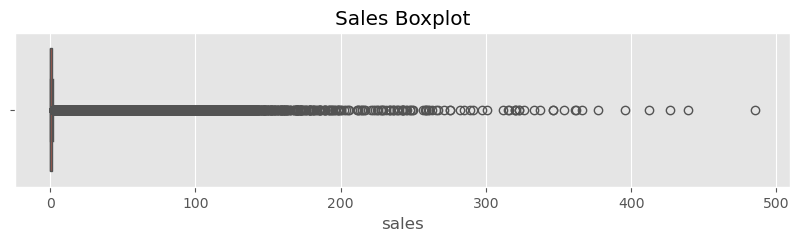

In [15]:
plt.figure(figsize=(10, 2))
sns.boxplot(x=sample_df["sales"])
plt.title("Sales Boxplot")
plt.tight_layout()
plt.show()


## 9. Time Series Analysis — Daily Total Sales

### Objective
Understand the overall sales trend, seasonality, and volatility over time.

### Method
Aggregate sales by date and plot as a time series.

### Observation
- Clear upward trend from 2011 to 2016.  
- Weekly seasonality visible (dips mid-week).  
- Some sharp drops likely correspond to missing data days or holidays.

### Business Interpretation
Business is growing year-over-year. Weekly patterns suggest weekend-driven demand.

### Decision
Include year-over-year trend features and day-of-week encoding in the model.


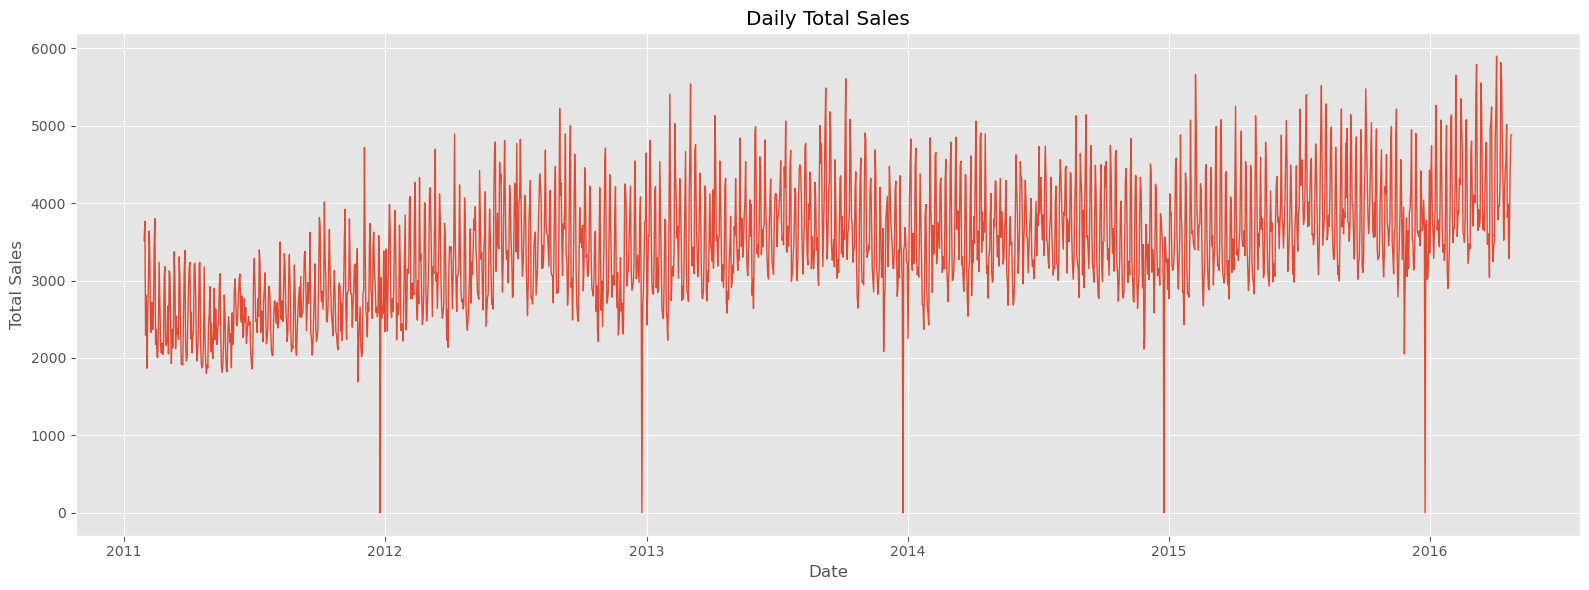

In [19]:
daily_sales = sample_df.groupby("date", as_index=False)["sales"].sum()
daily_sales["date"] = pd.to_datetime(daily_sales["date"])

plt.figure(figsize=(16, 6))
plt.plot(daily_sales["date"], daily_sales["sales"], linewidth=1)
plt.title("Daily Total Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


## 10. Monthly Analysis

### Objective
Identify which months have higher or lower average sales.

### Method
Compute mean sales grouped by month.

### Observation
- Peak months: August (1.17), September (1.17), July (1.16)  
- Low months: May (1.07), December (1.09), November (1.09)

### Business Interpretation
Summer months show slightly higher average sales; holiday months dip possibly due to data coverage.

### Decision
Add month as a cyclical feature (sin/cos encoding) in the model.


In [22]:
sample_df.groupby("month")["sales"].mean().sort_values(ascending=False)


weekday
Saturday     1.366534
Sunday       1.348946
Friday       1.120472
Monday       1.080639
Tuesday      1.001079
Thursday     0.997767
Wednesday    0.986365
Name: sales, dtype: float64

## 11. Weekday Analysis

### Objective
Determine the day-of-week effect on average sales.

### Method
Compute mean sales grouped by weekday.

### Observation
- Saturday: 1.37 (highest)  
- Sunday: 1.35  
- Wednesday: 0.99 (lowest)  
- Weekend sales are ~36% higher than mid-week.

### Business Interpretation
Strong weekend effect confirms grocery shopping peaks on Sat/Sun.

### Decision
Encode weekday as a feature; consider separate weekend indicator.


In [24]:
sample_df.groupby("weekday")["sales"].mean().sort_values(ascending=False)


snap_CA
0    1.098858
1    1.190595
Name: sales, dtype: float64

## 12. Event Analysis

### Objective
Assess whether calendar events (holidays, sporting, religious) impact average sales.

### Method
Group by `event_type_1` and compute count and mean sales.

### Observation
- Cultural events: mean 1.13 (106K records)  
- Sporting events: mean 1.13 (49K records)  
- Religious events: mean 1.11 (159K records)  
- National events: mean 0.97 (156K records) — **lowest**

### Business Interpretation
National holidays (e.g., Independence Day) slightly reduce sales, possibly due to store closures. Cultural and sporting events mildly boost sales.

### Decision
Add binary event-type indicators as features. National events may need a separate flag.


In [32]:
sample_df.groupby("event_type_1")["sales"].agg(["count", "mean"])


,count,mean
event_type_1,,
Cultural,106750,1.130698
National,155516,0.973231
Religious,158828,1.109408
Sporting,48868,1.125051


## 13. SNAP Analysis

### Objective
Measure the effect of SNAP (Supplemental Nutrition Assistance Program) benefit days on sales.

### Method
Compare mean sales on SNAP vs non-SNAP days for each state (CA, TX, WI).

### Observation
| State | SNAP=0 | SNAP=1 | Lift  |
|-------|--------|--------|-------|
| CA    | 1.10   | 1.19   | +8.2% |
| TX    | 1.09   | 1.20   | +10.1%|
| WI    | 1.09   | 1.20   | +9.7% |

### Business Interpretation
SNAP days consistently boost sales by ~8–10% across all states. This is a strong demand driver for food items.

### Decision
Include SNAP binary features per state. Consider SNAP × food_category interaction term.


In [26]:
for col in ["snap_CA", "snap_TX", "snap_WI"]:
    snap_effect = sample_df.groupby(col)["sales"].mean()
    lift = ((snap_effect[1] - snap_effect[0]) / snap_effect[0] * 100)
    print(f"{col}: SNAP=0 → {snap_effect[0]:.4f} | SNAP=1 → {snap_effect[1]:.4f} | Lift: +{lift:.1f}%")


snap_CA: SNAP=0 → 1.0989 | SNAP=1 → 1.1906 | Lift: +8.3%
snap_TX: SNAP=0 → 1.0928 | SNAP=1 → 1.2029 | Lift: +10.1%
snap_WI: SNAP=0 → 1.0943 | SNAP=1 → 1.1998 | Lift: +9.7%


## 14. Store Analysis

### Objective
Rank stores by total sales volume to identify top and bottom performers.

### Method
Aggregate total sales by `store_id` and sort descending.

### Observation
- Top store: **CA_3** (1.12M) — nearly 3× the lowest.  
- Bottom store: **CA_4** (411K).  
- CA stores dominate the top; WI and TX stores are mid-to-lower range.

### Business Interpretation
Store size and market area drive large volume differences. CA_3 is likely a high-traffic supercenter.

### Decision
Add store-level features (avg sales, store tier) to help the model learn store-specific patterns.


In [28]:
sample_df.groupby("store_id")["sales"].sum().sort_values(ascending=False)


store_id
CA_3    1121014
CA_1     772209
TX_2     723563
WI_2     652499
WI_3     648331
TX_3     609789
CA_2     572080
TX_1     558847
WI_1     516198
CA_4     411015
Name: sales, dtype: int64

## 15. Department Analysis

### Objective
Understand sales contribution by department to prioritize feature engineering.

### Method
Aggregate total sales by `dept_id` and sort descending.

### Observation
- **FOODS_3** dominates with 3.25M total sales (57% of all sales).  
- HOUSEHOLD_1: 1.15M  
- HOBBIES_2: 53K — smallest department.

### Business Interpretation
Food is the primary revenue driver. Hobbies contribute minimally. Department-level features will carry strong predictive signal.

### Decision
Encode department as a categorical feature. Consider department-specific models for FOODS_3.


In [31]:
sample_df.groupby("dept_id")["sales"].sum().sort_values(ascending=False)


dept_id
FOODS_3        3252961
HOUSEHOLD_1    1148205
FOODS_2         762284
HOBBIES_1       563037
FOODS_1         507914
HOUSEHOLD_2     297775
HOBBIES_2        53369
Name: sales, dtype: int64

## 16. Sell Price Analysis

### Objective
Understand the pricing distribution and its relationship with sales.

### Method
Descriptive statistics and histogram of `sell_price` (excluding NaN).

### Observation
- Mean price: $4.41, median: $3.47 — right-skewed.  
- Price range: $0.01 – $107.32.  
- Most items are priced below $6.

### Business Interpretation
Most products are low-cost groceries. High-price items are rare (likely household/hobby categories).

### Decision
Price should be included as a feature. Consider price binning or log transformation.


In [ ]:
sample_df["sell_price"].describe()


count    4.602801e+06
mean     4.408981e+00
std      3.404975e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

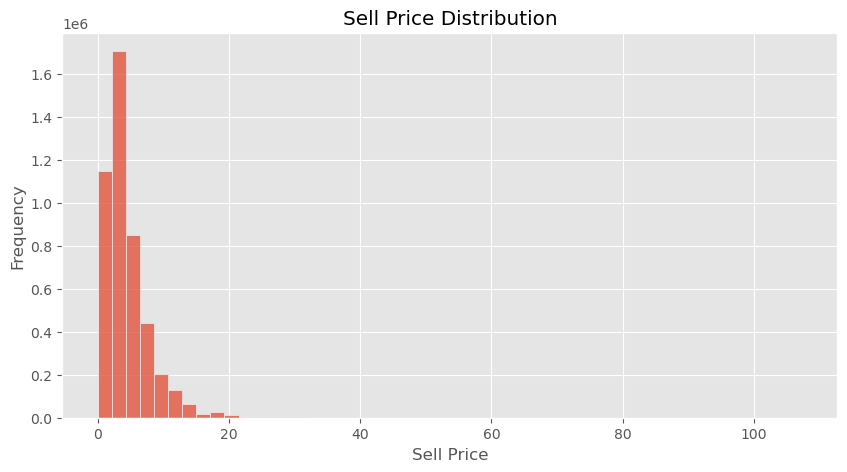

In [34]:
plt.figure(figsize=(10, 5))
sns.histplot(sample_df["sell_price"].dropna(), bins=50)
plt.title("Sell Price Distribution")
plt.xlabel("Sell Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 17. Price–Sales Correlation

### Objective
Quantify the linear relationship between price and sales volume.

### Method
Compute Pearson correlation between `sales` and `sell_price`.

### Observation
Correlation = **−0.15** — weak negative relationship.

### Business Interpretation
Higher-priced items sell slightly fewer units, but the effect is small. Price alone is not a strong predictor; interaction with category and promotions likely matters more.

### Decision
Include `sell_price` as a feature but expect limited linear contribution. Explore price × category interactions in feature engineering.


In [35]:
sample_df[["sales", "sell_price"]].corr()


,sales,sell_price
sales,1.000000,-0.150595
sell_price,-0.150595,1.000000


## 18. Final Business Insights

| # | Insight | Impact |
|---|---------|--------|
| 1 | Sales are zero-inflated and heavily right-skewed | Model must handle zeros; consider log(1+x) |
| 2 | Weekend sales are ~36% higher than mid-week | Encode weekday; add weekend flag |
| 3 | SNAP days boost sales by 8–10% across all states | Include SNAP binary features per state |
| 4 | FOODS_3 department drives 57% of total sales | Department-level features are high-signal |
| 5 | CA_3 store is the top performer (3× bottom store) | Store-level encoding required |
| 6 | Event types show mild sales variation | Binary event indicators suffice |
| 7 | Price has weak negative correlation (r = −0.15) | Include price but explore interactions |
| 8 | Upward year-over-year trend 2011–2016 | Include year/trend feature |
| 9 | 21% of sell_price values are NaN | Impute or flag during preprocessing |
| 10 | Event columns are >91% null | Encode as has_event binary flag |


# Day 3 Summary

## Objective Achieved
Completed a structured EDA on the M5 sampled dataset, identifying data quality issues, distribution characteristics, and key demand drivers.

## Key Findings
- Sales distribution is extremely zero-inflated with a heavy right tail.
- Strong temporal patterns: weekday effects (Sat/Sun peak), monthly seasonality, and year-over-year growth.
- SNAP benefit days increase sales by ~8–10%.
- FOODS_3 and CA_3 dominate volume.
- Price–sales correlation is weakly negative (−0.15).

## Main Business Insights
Demand is driven by time features (weekday, month, trend), SNAP benefits, and product category. Price has limited direct influence on daily unit sales.

## Important Decisions
1. Log-transform sales or use zero-aware models.
2. Encode weekday, month, and SNAP as features.
3. Create binary event flags instead of using sparse event columns.
4. Impute or flag missing `sell_price` values.
5. Add store-level and department-level aggregated features.

## Challenges
- Extreme skew makes visualization and modeling non-trivial.
- High null rate in event columns requires careful encoding strategy.
- Missing sell_price must be handled without introducing bias.

## Next Step — Day 4: Data Preprocessing
- Handle missing values (sell_price imputation, event encoding).
- Feature engineering (lag features, rolling stats, price bins, SNAP interactions).
- Outlier treatment and transformations.
- Train/validation split respecting temporal order.
